<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Redes Neurais Artificiais (ANN - Artificial Neural Network) com Scikit-Learn em Python, sobre os dados da Lego**

Inteligência Artificial - ML com Scikit-learn

PARTE II - LAB

### DUPLA:
- João Avila - RA00332195
- Kauã Cavalheiro - RA00331660

### Dados (LEGO)

LEGO sets released from 1970 to 2022, including details on each set's theme, pieces, recommended age, retail price, and image.

https://mavenanalytics.io/data-playground/lego-sets


## TODO

LAB:

EM DUPLAS (Pairing)<br>
Entrega amanhã (24 horas) em atividade no MS Teams
- Entregar o link do .ipynb no GitHub

- Baixar os dados
- Carregar em data frame Pandas
- Exibir visualmente os dados faltantes
- Organizar e limpar os dados
- Completar os kits de lego (Lego Sets) sem preço
   - Modelagem: Usando redes neurais artificial (ANN)
   - Scikit-learn
- Realizar análise e visualizações
   

Baixando dados do site, com o comando do Linux `wget` e o magic **!**

In [1]:
!wget https://maven-datasets.s3.amazonaws.com/LEGO+Sets/LEGO+Sets.zip

--2026-09-30 13:07:19--  https://maven-datasets.s3.amazonaws.com/LEGO+Sets/LEGO+Sets.zip
Resolving maven-datasets.s3.amazonaws.com (maven-datasets.s3.amazonaws.com)... 16.15.207.47, 16.15.239.143, 16.15.199.7, ...
Connecting to maven-datasets.s3.amazonaws.com (maven-datasets.s3.amazonaws.com)|16.15.207.47|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 536301 (524K) [application/zip]
Saving to: ‘LEGO+Sets.zip’

LEGO+Sets.zip       100%[===================>] 523.73K  --.-KB/s    in 0.01s   

2026-09-30 13:07:19 (53.3 MB/s) - ‘LEGO+Sets.zip’ saved [536301/536301]



Descompactando arquivo zip

In [2]:
!unzip *.zip

Archive:  LEGO+Sets.zip
  inflating: lego_sets.csv           
  inflating: lego_sets_data_dictionary.csv  


Listando os arquivos na pasta atual

In [3]:
!ls -l

total 4380
-rw-r--r-- 1 root root 3936470 Jan  3  2024 lego_sets.csv
-rw-r--r-- 1 root root     532 Jan  3  2024 lego_sets_data_dictionary.csv
-rw-r--r-- 1 root root  536301 Jan  3  2024 LEGO+Sets.zip
drwxr-xr-x 1 root root    4096 Sep 16 13:26 sample_data


Importando LIBs de EDA (Exploratory Data Analisys)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno


Carregando e visualizando dados

In [5]:
lego_df = pd.read_csv('lego_sets.csv')

lego_df.head()

,set_id,name,year,theme,subtheme,themeGroup,category,pieces,minifigs,agerange_min,US_retailPrice,bricksetURL,thumbnailURL,imageURL
0,1-8,Small house set,1970,Minitalia,NaN,Vintage,Normal,67.0,NaN,NaN,NaN,https://brickset.com/sets/1-8,https://images.brickset.com/sets/small/1-8.jpg,https://images.brickset.com/sets/images/1-8.jpg
1,2-8,Medium house set,1970,Minitalia,NaN,Vintage,Normal,109.0,NaN,NaN,NaN,https://brickset.com/sets/2-8,https://images.brickset.com/sets/small/2-8.jpg,https://images.brickset.com/sets/images/2-8.jpg
2,3-6,Medium house set,1970,Minitalia,NaN,Vintage,Normal,158.0,NaN,NaN,NaN,https://brickset.com/sets/3-6,https://images.brickset.com/sets/small/3-6.jpg,https://images.brickset.com/sets/images/3-6.jpg
3,4-4,Large house set,1970,Minitalia,NaN,Vintage,Normal,233.0,NaN,NaN,NaN,https://brickset.com/sets/4-4,https://images.brickset.com/sets/small/4-4.jpg,https://images.brickset.com/sets/images/4-4.jpg
4,4-6,Mini House and Vehicles,1970,Samsonite,Model Maker,Vintage,Normal,NaN,NaN,NaN,NaN,https://brickset.com/sets/4-6,NaN,NaN


Buscando os valores faltantes (nulls)

In [6]:
# show missing values
lego_df.isnull().sum()

,0
set_id,0
name,0
year,0
theme,0
subtheme,3556
themeGroup,2
category,0
pieces,3924
minifigs,10058
agerange_min,11670


Visualizando valores faltantes (nulls)

<Axes: >

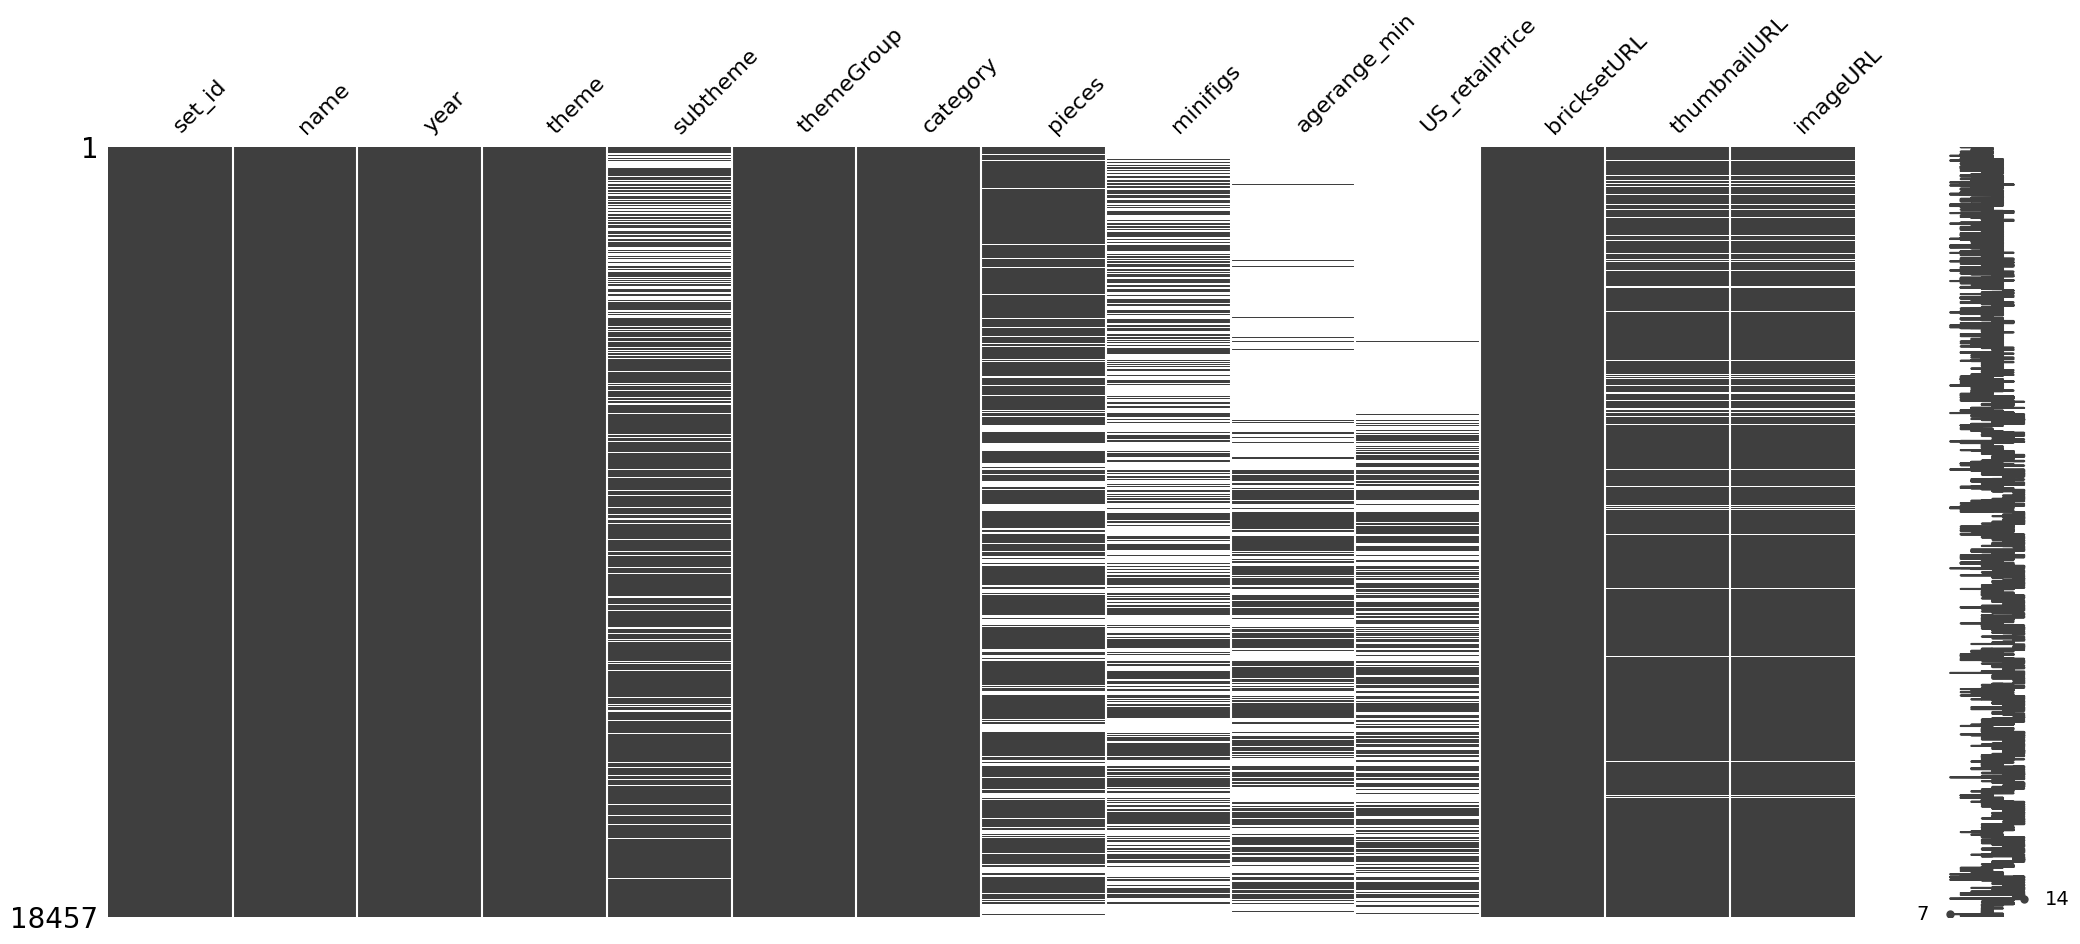

In [7]:
#Visualize missing values
msno.matrix(lego_df)


<Axes: >

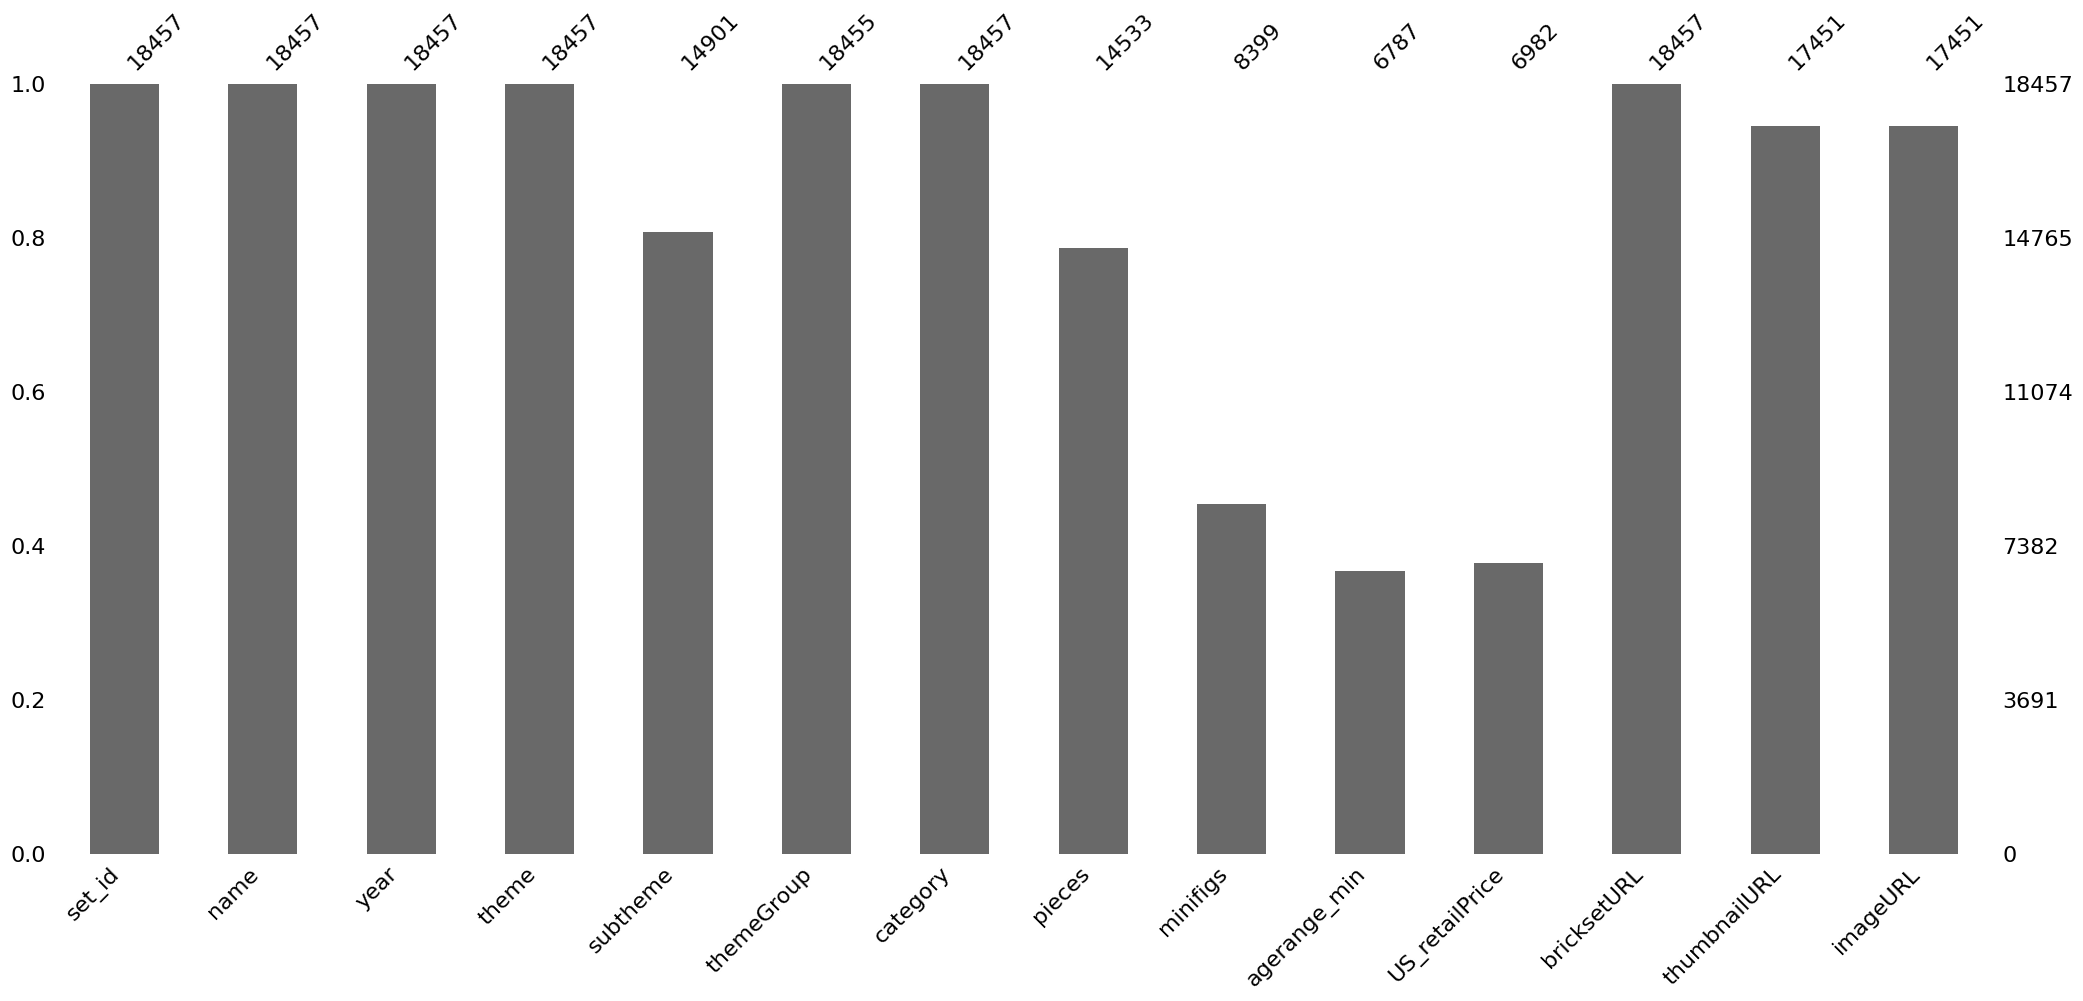

In [8]:
msno.bar(lego_df)


<Axes: >

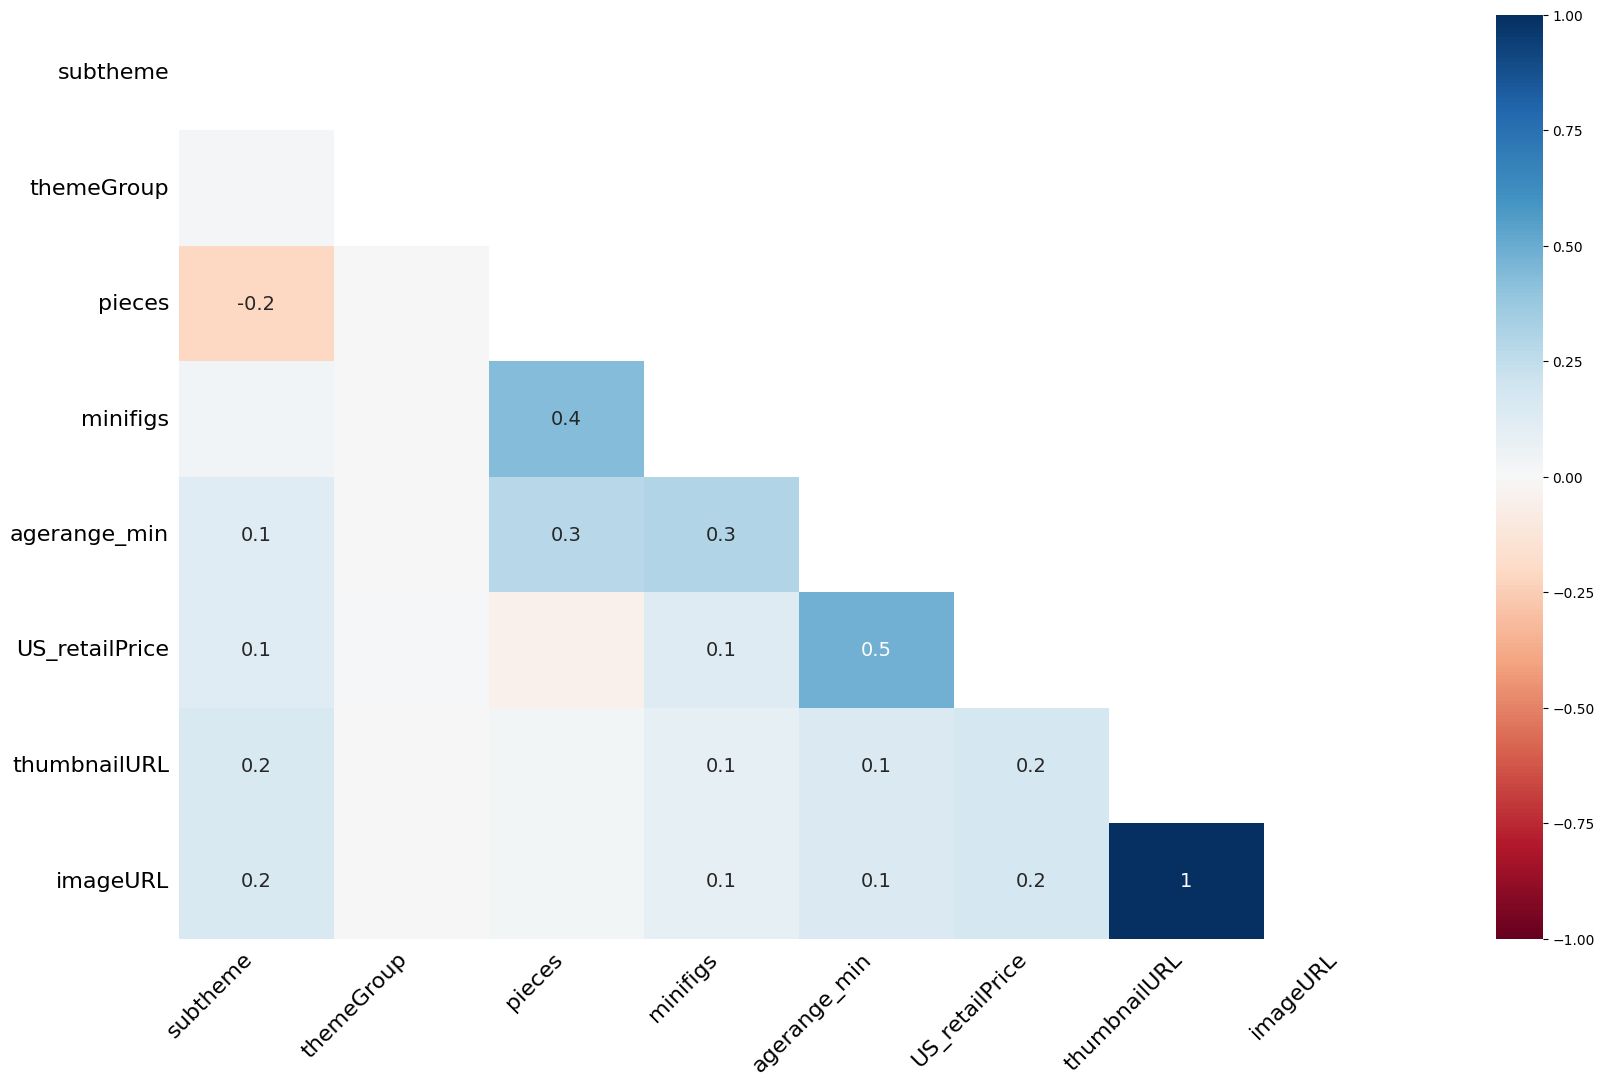

In [9]:
msno.heatmap(lego_df)


Atividade: Criar uma coluna nova `price` e completar usando o modelo de redes neurais do Scikit-Learn (ANN), todos os conjuntos de leve devem ter preço.

Quais as colunas importantes para prever o preço??

### 1. Organização e limpeza dos dados

Decisões de limpeza (todas aplicadas em uma **cópia** `df_clean`; o `lego_df` original permanece intacto):

| Coluna | Tratamento | Justificativa |
|---|---|---|
| `themeGroup` | moda | apenas 2 nulos |
| `subtheme` | categoria `'Unknown'` | ausência de subtema é informação em si |
| `pieces` | mediana por `category` (fallback: mediana global) + indicador `pieces_missing` | kits de categorias diferentes têm tamanhos muito diferentes; o indicador preserva a informação de que o valor era desconhecido |
| `minifigs` | 0 | nulo indica que o kit não traz minifiguras |
| `agerange_min` | removida | proporção muito alta de nulos (calculada abaixo) |
| `set_id`, `name`, URLs | removidas | identificadores/links, não são features |

set_id duplicados      : 0
linhas 100% duplicadas : 0
agerange_min: 63.2% de nulos -> coluna removida

Nulos por coluna após a limpeza:
year                  0
pieces                0
minifigs              0
pieces_missing        0
theme                 0
subtheme              0
themeGroup            0
category              0
US_retailPrice    11475
dtype: int64


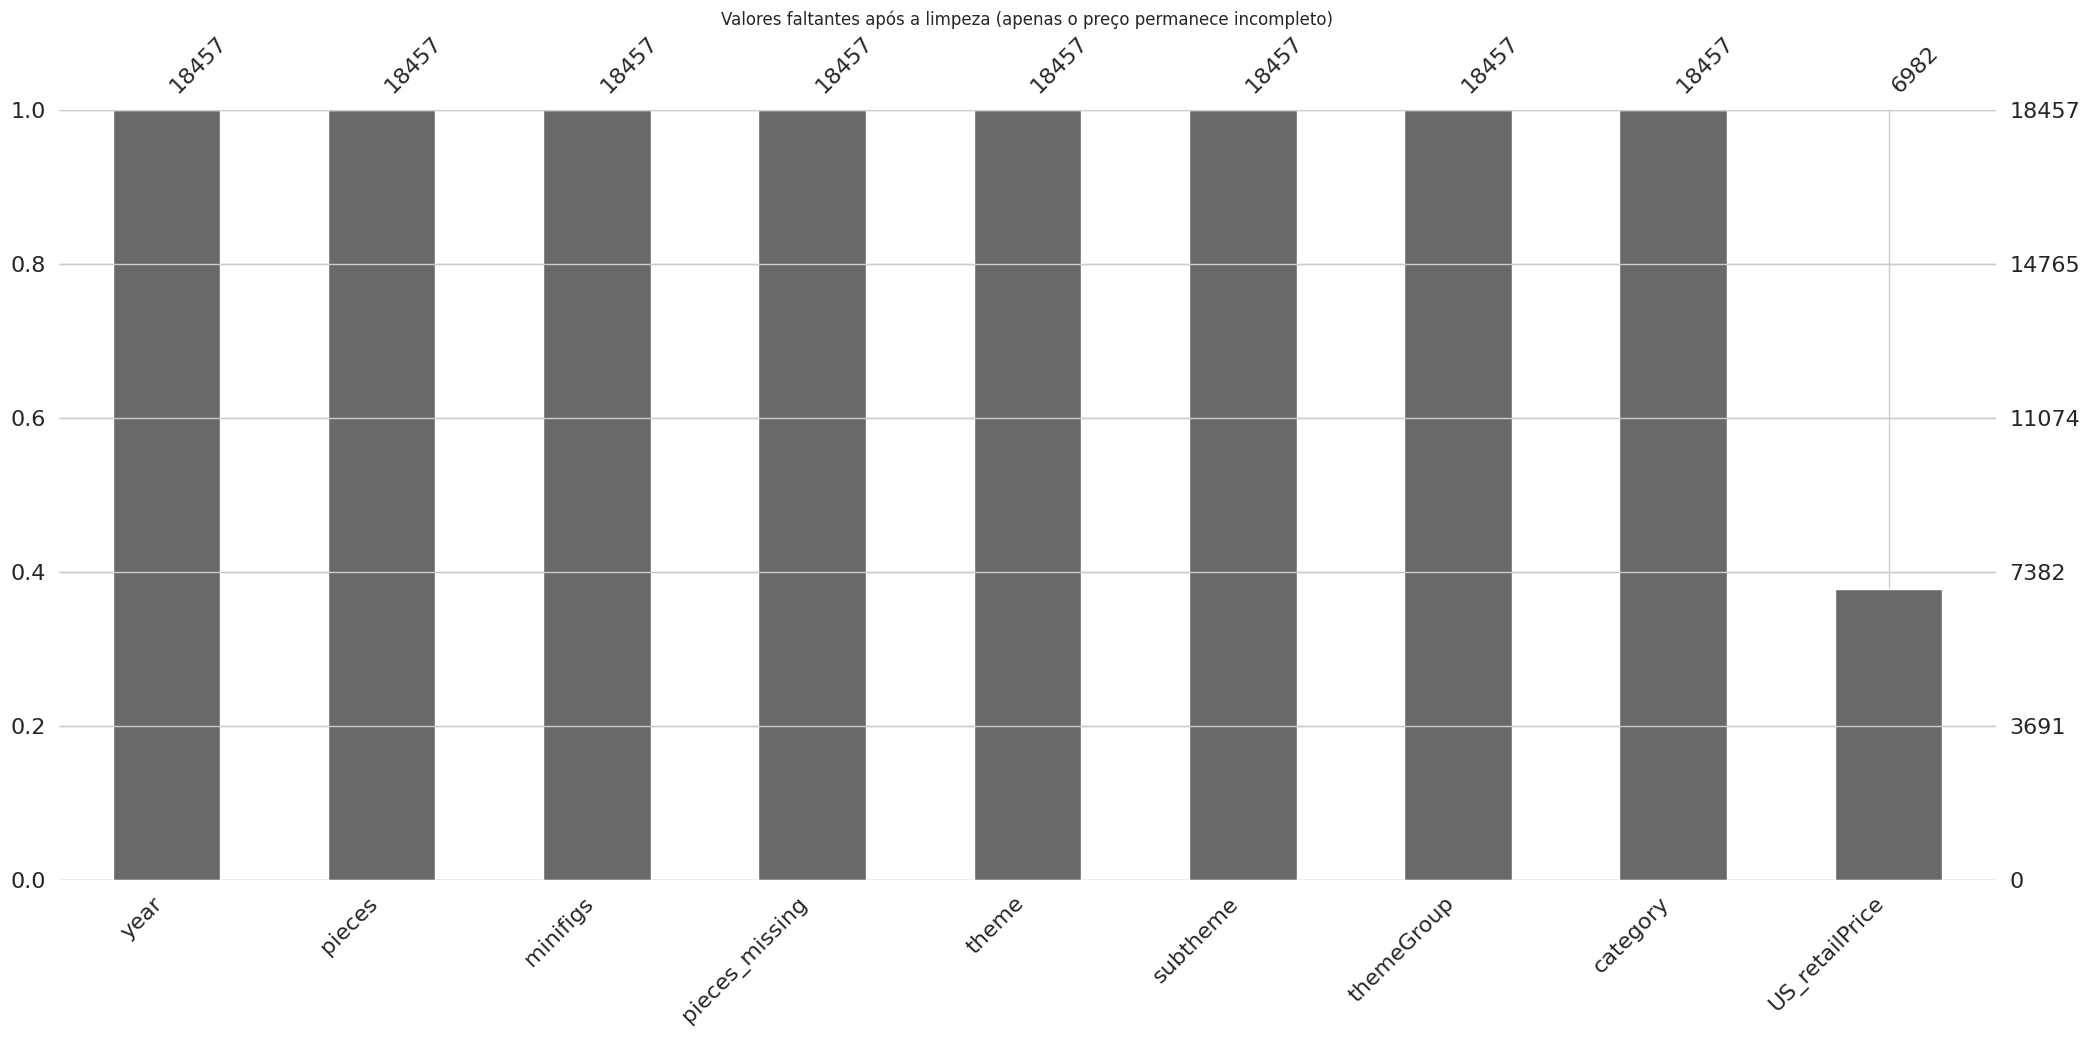

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ------------------------------------------------------------------
# 1.1 Duplicatas
# ------------------------------------------------------------------
print("set_id duplicados      :", lego_df.duplicated(subset='set_id').sum())
print("linhas 100% duplicadas :", lego_df.duplicated().sum())
lego_df = lego_df.drop_duplicates().reset_index(drop=True)

# ------------------------------------------------------------------
# 1.2 Tratamento dos valores faltantes (em uma cópia)
# ------------------------------------------------------------------
df_clean = lego_df.copy()

df_clean['themeGroup'] = df_clean['themeGroup'].fillna(df_clean['themeGroup'].mode()[0])
df_clean['subtheme']   = df_clean['subtheme'].fillna('Unknown')

df_clean['pieces_missing'] = df_clean['pieces'].isnull().astype(int)
df_clean['pieces'] = df_clean.groupby('category')['pieces'].transform(lambda s: s.fillna(s.median()))
df_clean['pieces'] = df_clean['pieces'].fillna(df_clean['pieces'].median())

df_clean['minifigs'] = df_clean['minifigs'].fillna(0)

pct_age_null = df_clean['agerange_min'].isnull().mean() * 100
print(f"agerange_min: {pct_age_null:.1f}% de nulos -> coluna removida")

# ------------------------------------------------------------------
# 1.3 Seleção de colunas para o modelo
# ------------------------------------------------------------------
num_cols = ['year', 'pieces', 'minifigs', 'pieces_missing']
cat_cols = ['theme', 'subtheme', 'themeGroup', 'category']
feature_cols = num_cols + cat_cols
TARGET = 'US_retailPrice'

model_df = df_clean[feature_cols + [TARGET]]

print("\nNulos por coluna após a limpeza:")
print(model_df.isnull().sum())

# Só o alvo (preço) deve continuar com nulos: são justamente os kits a completar
msno.bar(model_df)
plt.title("Valores faltantes após a limpeza (apenas o preço permanece incompleto)")
plt.show()

### 2. Modelagem com ANN (Scikit-Learn)

- **Pipeline único** (`ColumnTransformer` + `MLPRegressor`): a padronização e o one-hot são aprendidos apenas no treino, sem vazamento, e o mesmo pipeline é usado para prever os kits sem preço.
- **Alvo em escala log** (`log1p`/`expm1` via `TransformedTargetRegressor`): preços são muito assimétricos; isso estabiliza o treino e evita previsões negativas.
- Treino/teste 80/20 apenas sobre os kits que **têm** preço.

In [11]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------------
# 2.1 Separação: kits COM preço (treino/teste) x SEM preço (a completar)
# ------------------------------------------------------------------
known_mask = model_df[TARGET].notnull()
X_known   = model_df.loc[known_mask,  feature_cols]
y_known   = model_df.loc[known_mask,  TARGET]
X_unknown = model_df.loc[~known_mask, feature_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X_known, y_known, test_size=0.2, random_state=RANDOM_STATE)

print(f"Kits com preço: {len(X_known)}  (treino={len(X_train)}, teste={len(X_test)})")
print(f"Kits sem preço: {len(X_unknown)}")

# ------------------------------------------------------------------
# 2.2 Pipeline: pré-processamento + ANN
# ------------------------------------------------------------------
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

ann = Pipeline([
    ('prep', preprocess),
    ('mlp', MLPRegressor(hidden_layer_sizes=(100, 50),
                         activation='relu',
                         solver='adam',
                         max_iter=500,
                         early_stopping=True,
                         random_state=RANDOM_STATE)),
])

model = TransformedTargetRegressor(regressor=ann, func=np.log1p, inverse_func=np.expm1)

print("\nTreinando a rede neural...")
model.fit(X_train, y_train)

# ------------------------------------------------------------------
# 2.3 Avaliação (escala original, em US$)
# ------------------------------------------------------------------
y_pred_test = model.predict(X_test)
mae  = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2   = r2_score(y_test, y_pred_test)

print(f"R²   (teste): {r2:.4f}")
print(f"MAE  (teste): US$ {mae:.2f}")
print(f"RMSE (teste): US$ {rmse:.2f}")

Kits com preço: 6982  (treino=5585, teste=1397)
Kits sem preço: 11475

Treinando a rede neural...
R²   (teste): 0.8579
MAE  (teste): US$ 8.06
RMSE (teste): US$ 21.32


### 3. Criação da coluna `price` (todos os kits com preço)

- `price` = preço real (`US_retailPrice`) quando existe; caso contrário, o preço previsto pela ANN.
- `price_is_predicted` marca a origem de cada valor, para que as análises possam separar dado real de dado imputado.
- `US_retailPrice` original **não é alterado**.
- Previsões são limitadas à faixa de preços reais observados (piso = menor preço real, teto = maior preço real): nenhum kit fica com preço 0/negativo e a rede não extrapola para valores absurdos.

In [12]:
# ------------------------------------------------------------------
# 3.1 Predição dos kits sem preço
# ------------------------------------------------------------------
price_floor, price_ceiling = y_known.min(), y_known.max()
raw_pred = model.predict(X_unknown)
n_below = int((raw_pred < price_floor).sum())
n_above = int((raw_pred > price_ceiling).sum())
predicted_prices = np.round(np.clip(raw_pred, price_floor, price_ceiling), 2)

print(f"Faixa de preços reais observados: US$ {price_floor:.2f} a US$ {price_ceiling:.2f}")
print(f"Previsões abaixo do piso (ajustadas): {n_below} de {len(raw_pred)}")
print(f"Previsões acima do teto (ajustadas) : {n_above} de {len(raw_pred)}")

# ------------------------------------------------------------------
# 3.2 Nova coluna `price` (+ marcador de origem)
# ------------------------------------------------------------------
lego_df['price_is_predicted'] = lego_df[TARGET].isnull()
lego_df['price'] = lego_df[TARGET]
lego_df.loc[X_unknown.index, 'price'] = predicted_prices

# ------------------------------------------------------------------
# 3.3 Verificação: TODOS os kits devem ter preço válido
# ------------------------------------------------------------------
assert lego_df['price'].notnull().all(), "Existem kits sem preço!"
assert (lego_df['price'] > 0).all(), "Existem kits com preço <= 0!"
assert lego_df.loc[~lego_df['price_is_predicted'], 'price'].equals(
    lego_df.loc[~lego_df['price_is_predicted'], TARGET]), "Preços reais foram alterados!"

print("\n✔ Todos os kits possuem preço válido.")
print(f"  Total de kits        : {len(lego_df)}")
print(f"  Preços reais         : {(~lego_df['price_is_predicted']).sum()}")
print(f"  Preços previstos     : {lego_df['price_is_predicted'].sum()}")
print(f"  Nulos em `price`     : {lego_df['price'].isnull().sum()}")
print(f"  Faixa de `price`     : US$ {lego_df['price'].min():.2f} a US$ {lego_df['price'].max():.2f}")

lego_df[['set_id', 'name', 'year', 'pieces', TARGET, 'price', 'price_is_predicted']].head(10)

Faixa de preços reais observados: US$ 1.49 a US$ 849.99
Previsões abaixo do piso (ajustadas): 0 de 11475
Previsões acima do teto (ajustadas) : 2 de 11475

✔ Todos os kits possuem preço válido.
  Total de kits        : 18457
  Preços reais         : 6982
  Preços previstos     : 11475
  Nulos em `price`     : 0
  Faixa de `price`     : US$ 1.49 a US$ 849.99


,set_id,name,year,pieces,US_retailPrice,price,price_is_predicted
0,1-8,Small house set,1970,67.0,NaN,14.96,True
1,2-8,Medium house set,1970,109.0,NaN,16.77,True
2,3-6,Medium house set,1970,158.0,NaN,19.21,True
3,4-4,Large house set,1970,233.0,NaN,23.62,True
4,4-6,Mini House and Vehicles,1970,NaN,NaN,17.52,True
5,078-1,Roadway Base Plate 50X50,1970,1.0,NaN,9.07,True
6,104-1,4.5V Replacement Motor,1970,1.0,NaN,29.26,True
7,126-1,Steam Locomotive (Push),1970,60.0,NaN,34.40,True
8,157-3,4 Car Auto Transport,1970,65.0,NaN,10.84,True
9,242-4,Big Model Book,1970,NaN,NaN,49.58,True


### 4. Quais as colunas importantes para prever o preço?

Usamos **permutation importance** sobre o pipeline completo, no conjunto de teste: embaralha-se uma coluna *original* por vez e mede-se o aumento do erro (MAE, em US$). Como o embaralhamento é feito antes do one-hot, cada variável categórica (ex.: `theme`, com centenas de níveis) recebe **uma única** nota, o que torna o ranking comparável. Complementamos com a correlação de Spearman das variáveis numéricas com o preço.

,coluna,aumento_MAE_US$,desvio
0,pieces,24.110063,0.830384
1,subtheme,6.609876,0.440767
2,theme,5.397268,0.395346
3,minifigs,2.926281,0.215259
4,themeGroup,2.670757,0.197830
5,pieces_missing,2.233935,0.212271
6,category,1.121890,0.225008
7,year,0.926358,0.122642


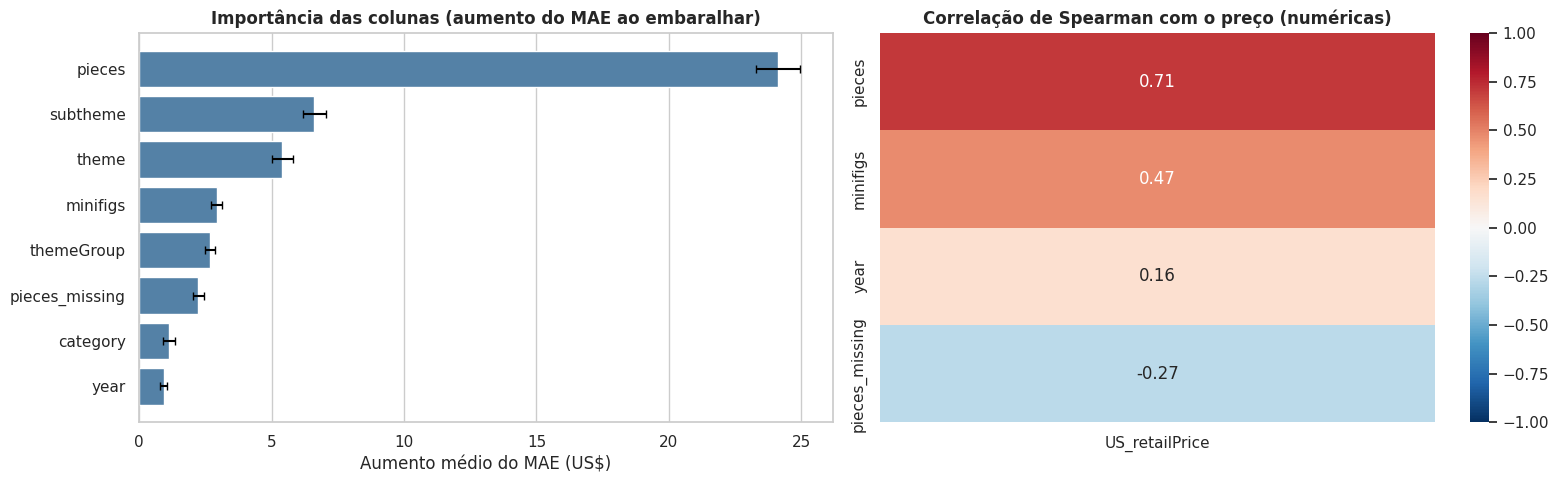

RESPOSTA - colunas mais importantes para prever o preço (ordem decrescente):
  1. pieces          (MAE sobe US$ 24.11)
  2. subtheme        (MAE sobe US$ 6.61)
  3. theme           (MAE sobe US$ 5.40)

Colunas relevantes (MAE sobe > 5% ao embaralhar): ['pieces', 'subtheme', 'theme', 'minifigs', 'themeGroup', 'pieces_missing', 'category', 'year']
Colunas com contribuição pequena ou nula                : []


In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring='neg_mean_absolute_error', n_jobs=-1)

importance_df = (pd.DataFrame({'coluna': feature_cols,
                               'aumento_MAE_US$': perm.importances_mean,
                               'desvio': perm.importances_std})
                   .sort_values('aumento_MAE_US$', ascending=False)
                   .reset_index(drop=True))
display(importance_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=importance_df, y='coluna', x='aumento_MAE_US$', color='steelblue', ax=axes[0])
axes[0].errorbar(importance_df['aumento_MAE_US$'], range(len(importance_df)),
                 xerr=importance_df['desvio'], fmt='none', ecolor='black', capsize=3)
axes[0].set_title('Importância das colunas (aumento do MAE ao embaralhar)', fontweight='bold')
axes[0].set_xlabel('Aumento médio do MAE (US$)')
axes[0].set_ylabel('')

corr = (df_clean.loc[known_mask, num_cols + [TARGET]]
        .corr(method='spearman')[[TARGET]].drop(TARGET).sort_values(TARGET, ascending=False))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlação de Spearman com o preço (numéricas)', fontweight='bold')

plt.tight_layout()
plt.show()

# Conclusão gerada a partir dos resultados desta execução
limiar = 0.05 * mae   # relevante = piora o erro em mais de 5% do MAE do modelo
relevantes = importance_df[importance_df['aumento_MAE_US$'] > limiar]['coluna'].tolist()
irrelevantes = importance_df[importance_df['aumento_MAE_US$'] <= limiar]['coluna'].tolist()
print("RESPOSTA - colunas mais importantes para prever o preço (ordem decrescente):")
for i, row in importance_df.head(3).iterrows():
    print(f"  {i+1}. {row['coluna']:<15} (MAE sobe US$ {row['aumento_MAE_US$']:.2f})")
print("\nColunas relevantes (MAE sobe > 5% ao embaralhar):", relevantes)
print("Colunas com contribuição pequena ou nula                :", irrelevantes)

### 5. Análise e visualizações

Primeiro, a qualidade do modelo; depois, a análise dos preços separando **dado real** de **dado imputado**, para não tirar conclusões enviesadas pelo modelo.

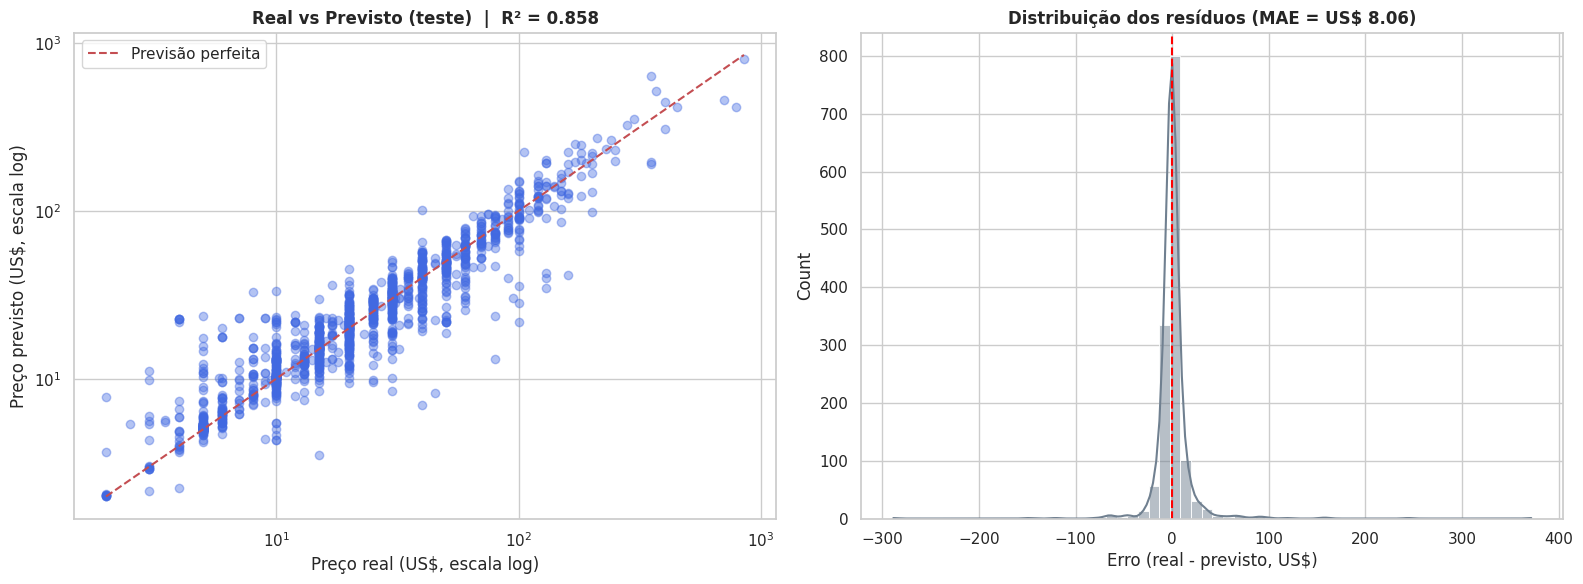

In [14]:
# ------------------------------------------------------------------
# 5.1 Qualidade do modelo (conjunto de teste)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

lim = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].scatter(y_test, y_pred_test, alpha=0.4, color='royalblue')
axes[0].plot(lim, lim, 'r--', label='Previsão perfeita')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title(f'Real vs Previsto (teste)  |  R² = {r2:.3f}', fontweight='bold')
axes[0].set_xlabel('Preço real (US$, escala log)')
axes[0].set_ylabel('Preço previsto (US$, escala log)')
axes[0].legend()

residuos = y_test - y_pred_test
sns.histplot(residuos, bins=60, kde=True, color='slategray', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f'Distribuição dos resíduos (MAE = US$ {mae:.2f})', fontweight='bold')
axes[1].set_xlabel('Erro (real - previsto, US$)')

plt.tight_layout()
plt.show()

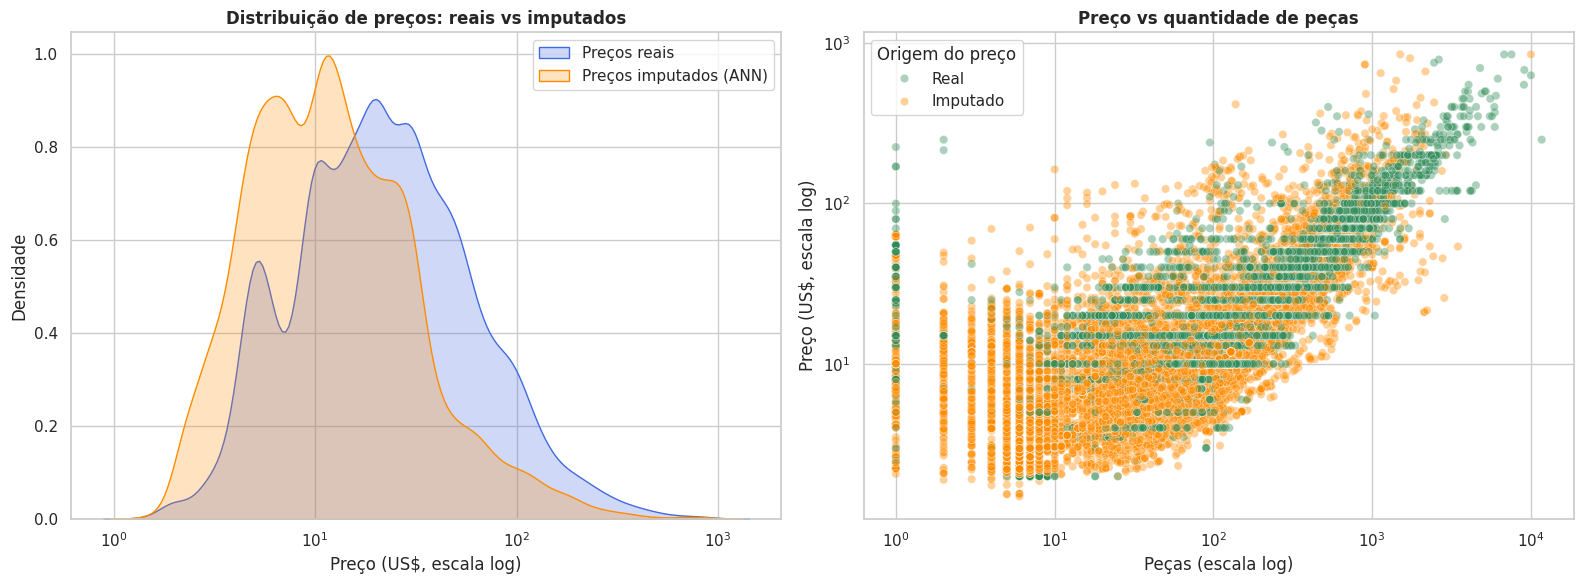

In [15]:
# ------------------------------------------------------------------
# 5.2 Preços reais vs imputados: distribuição e relação com nº de peças
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.kdeplot(lego_df.loc[~lego_df['price_is_predicted'], 'price'], log_scale=True,
            fill=True, color='royalblue', label='Preços reais', ax=axes[0])
sns.kdeplot(lego_df.loc[lego_df['price_is_predicted'], 'price'], log_scale=True,
            fill=True, color='darkorange', label='Preços imputados (ANN)', ax=axes[0])
axes[0].set_title('Distribuição de preços: reais vs imputados', fontweight='bold')
axes[0].set_xlabel('Preço (US$, escala log)')
axes[0].set_ylabel('Densidade')
axes[0].legend()

df_plot = lego_df[lego_df['pieces'] > 0]
sns.scatterplot(data=df_plot, x='pieces', y='price', hue='price_is_predicted',
                palette={False: 'seagreen', True: 'darkorange'}, alpha=0.4, ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title('Preço vs quantidade de peças', fontweight='bold')
axes[1].set_xlabel('Peças (escala log)')
axes[1].set_ylabel('Preço (US$, escala log)')
handles, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles, ['Real', 'Imputado'], title='Origem do preço')

plt.tight_layout()
plt.show()

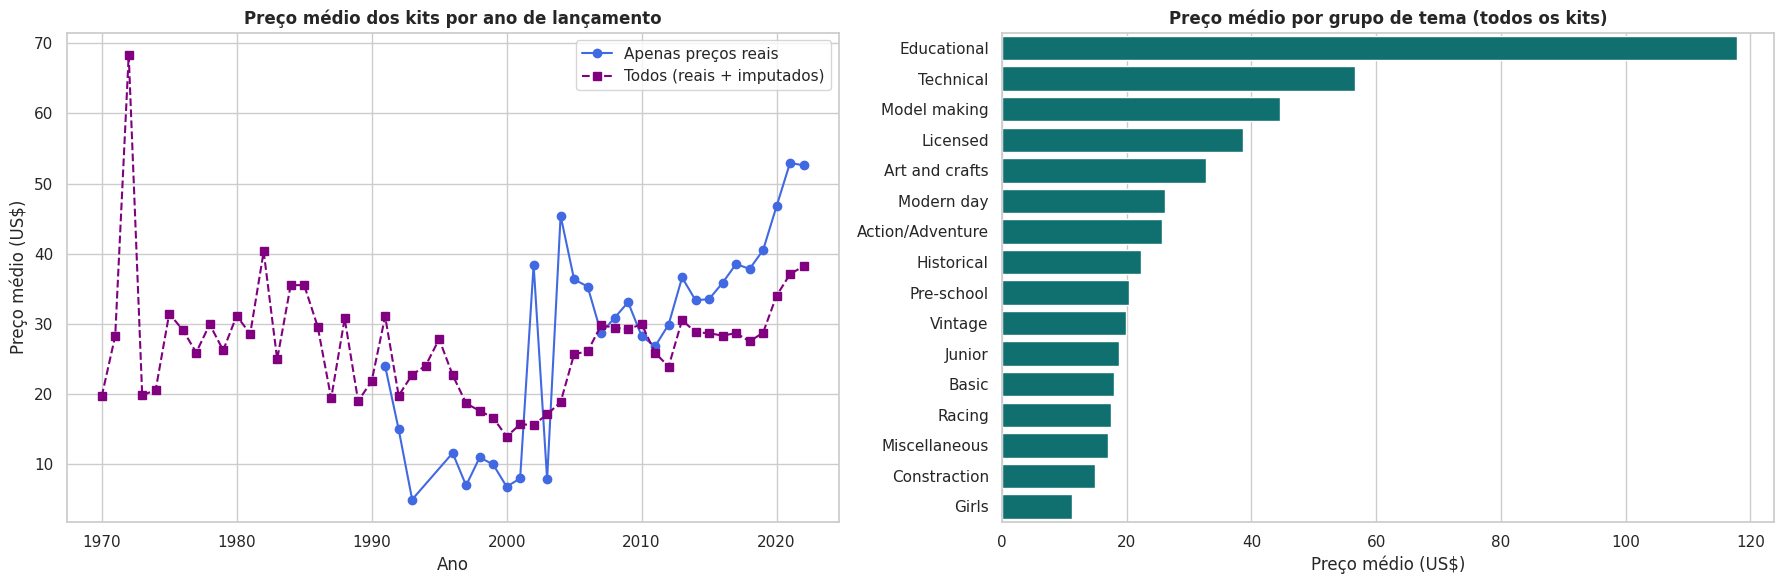

Kits por grupo de tema (para contextualizar as médias):


,themeGroup,preço médio (US$),nº de kits
0,Educational,117.887708,493
1,Technical,56.623486,588
2,Model making,44.611405,719
3,Licensed,38.712296,2509
4,Art and crafts,32.728571,84
5,Modern day,26.164489,2357
6,Action/Adventure,25.663457,1397
7,Historical,22.267949,473
8,Pre-school,20.328341,1537
9,Vintage,19.965377,305


In [16]:
# ------------------------------------------------------------------
# 5.3 Evolução do preço por ano e preço por grupo de tema
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

only_real = lego_df[~lego_df['price_is_predicted']].groupby('year')['price'].mean()
all_prices = lego_df.groupby('year')['price'].mean()
axes[0].plot(only_real.index, only_real.values, marker='o', color='royalblue', label='Apenas preços reais')
axes[0].plot(all_prices.index, all_prices.values, marker='s', color='purple', linestyle='--',
             label='Todos (reais + imputados)')
axes[0].set_title('Preço médio dos kits por ano de lançamento', fontweight='bold')
axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Preço médio (US$)')
axes[0].legend()

by_group = (lego_df.groupby('themeGroup')['price'].agg(['mean', 'count'])
            .sort_values('mean', ascending=False).reset_index())
sns.barplot(data=by_group, y='themeGroup', x='mean', color='teal', ax=axes[1])
axes[1].set_title('Preço médio por grupo de tema (todos os kits)', fontweight='bold')
axes[1].set_xlabel('Preço médio (US$)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print("Kits por grupo de tema (para contextualizar as médias):")
display(by_group.rename(columns={'mean': 'preço médio (US$)', 'count': 'nº de kits'}))